In [ ]:
# Install TensorFlow
# !pip install -q tensorflow-gpu==2.0.0-beta1

try:
  %tensorflow_version 2.x  # Colab only.
except Exception:
  pass

import tensorflow as tf
print(tf.__version__)

Colab only includes TensorFlow 2.x; %tensorflow_version has no effect.
2.18.0


In [ ]:
# Other imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Get the data
!wget https://raw.githubusercontent.com/lazyprogrammer/machine_learning_examples/master/tf2.0/moore.csv

--2025-06-08 12:36:36--  https://raw.githubusercontent.com/lazyprogrammer/machine_learning_examples/master/tf2.0/moore.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2302 (2.2K) [text/plain]
Saving to: ‘moore.csv.1’

moore.csv.1         100%[===================>]   2.25K  --.-KB/s    in 0s      

2025-06-08 12:36:37 (16.0 MB/s) - ‘moore.csv.1’ saved [2302/2302]



In [ ]:
# Load in the data
data = pd.read_csv('moore.csv', header=None).to_numpy()

In [ ]:
data

array([[       1971,        2300],
       [       1972,        3500],
       [       1973,        2500],
       [       1973,        2500],
       [       1974,        4100],
       [       1974,        4500],
       [       1974,        8000],
       [       1975,        3510],
       [       1976,        5000],
       [       1976,        8500],
       [       1976,        6500],
       [       1978,        9000],
       [       1978,       29000],
       [       1979,       17500],
       [       1979,       29000],
       [       1979,       68000],
       [       1981,       11500],
       [       1982,       55000],
       [       1982,      134000],
       [       1983,       22000],
       [       1984,       63000],
       [       1984,      190000],
       [       1985,      275000],
       [       1985,       25000],
       [       1985,       16000],
       [       1986,      110000],
       [       1986,      375000],
       [       1986,       30000],
       [       1987,

In [ ]:
X = data[:,0].reshape(-1, 1) # make it a 2-D array of size N x D where D = 1
Y = data[:,1]

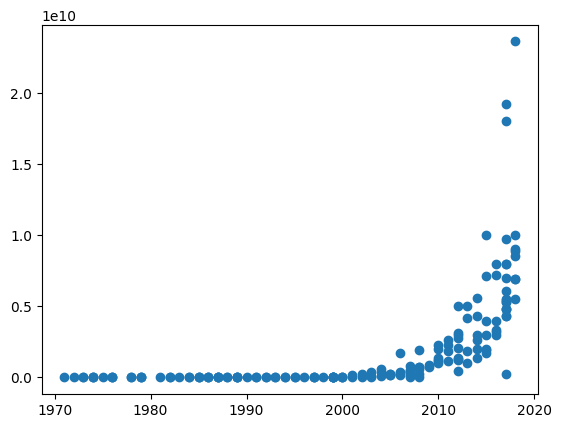

In [ ]:
# Plot the data - it is exponential!
plt.scatter(X, Y)

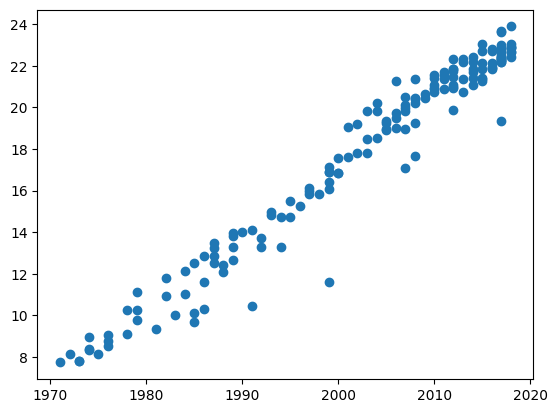

In [ ]:
# Since we want a linear model, let's take the log
Y = np.log(Y)
plt.scatter(X, Y)
# that's better

In [ ]:
# Let's also center the X data so the values are not too large
# We could scale it too but then we'd have to reverse the transformation later
X = X - X.mean()

In [ ]:
# Now create our Tensorflow model
model = tf.keras.models.Sequential([
  tf.keras.layers.Input(shape=(1,)),
  tf.keras.layers.Dense(1)
])


In [ ]:
model.compile(optimizer=tf.keras.optimizers.SGD(0.001, 0.9), loss='mse')
# model.compile(optimizer='adam', loss='mse')


In [ ]:
# learning rate scheduler
def schedule(epoch, lr):
  if epoch >= 50:
    return 0.0001
  return 0.001


scheduler = tf.keras.callbacks.LearningRateScheduler(schedule)


# Train the model
r = model.fit(X, Y, epochs=200, callbacks=[scheduler])

Epoch 1/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 401.5143 - learning_rate: 0.0010
Epoch 2/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 548.8421 - learning_rate: 0.0010
Epoch 3/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 562.2478 - learning_rate: 0.0010
Epoch 4/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 305.1900 - learning_rate: 0.0010
Epoch 5/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 179.5055 - learning_rate: 0.0010
Epoch 6/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 138.8389 - learning_rate: 0.0010
Epoch 7/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 95.3744 - learning_rate: 0.0010
Epoch 8/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 73.1957 - learning_rate: 0.0010
Epoch 9/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 55.0235 - learning_rate: 0.0010
Epoch 10/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 40.3512 - learning_rate: 0.0010
Epoch 11/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 32.4851 - learning_rate: 0.0010
Epoch 12/200

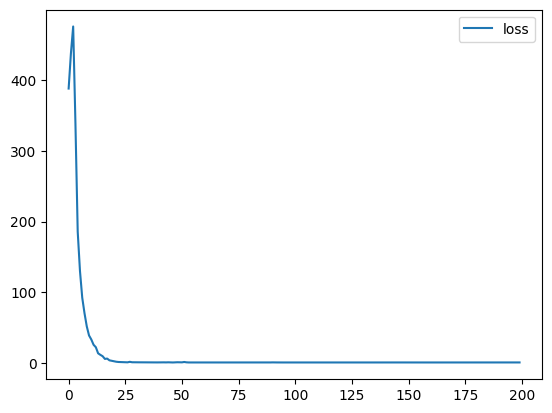

In [ ]:
# Plot the loss
plt.plot(r.history['loss'], label='loss')
plt.legend();

In [ ]:
model.layers

[<Dense name=dense, built=True>]

In [ ]:
# Get the slope of the line
# The slope of the line is related to the doubling rate of transistor count
print(model.layers) # Note: there is only 1 layer, the "Input" layer doesn't count
print(model.layers[0].get_weights())

[<Dense name=dense, built=True>]
[array([[0.33103225]], dtype=float32), array([17.754292], dtype=float32)]


In [ ]:
# The slope of the line is:
a = model.layers[0].get_weights()[0][0,0]

In [ ]:
a

np.float32(0.33103225)

Our original model for exponential growth is:

C
=
A
0
r
t
Where
C
 is transistor the count and
t
 is the year.

r
 is the rate of growth. For example, when
t
 goes from 1 to 2,
C
 increases by a factor of
r
. When
t
 goes from 2 to 3,
C
 increases by a factor of
r
 again.

When we take the log of both sides, we get:

log
C
=
log
r
∗
t
+
log
A
0
This is our linear equation:

^
y
=
a
x
+
b
Where:

^
y
=
log
C
a
=
log
r
x
=
t
b
=
log
A
0
We are interested in
r
, because that's the rate of growth. Given our regression weights, we know that:

a
=
0.34188038
so that:

r
=
e
0.34188038
=
1.4076
To find the time it takes for transistor count to double, we simply need to find the amount of time it takes for
C
 to increase to
2
C
.

Let's call the original starting time
t
, to correspond with the initial transistor count
C
.

Let's call the end time
t
′
, to correspond with the final transistor count
2
C
.

Then we also have:

2
C
=
A
0
r
t
′
Combine this with our original equation:

C
=
A
0
r
t
We get (by dividing the 2 equations):

2
C
/
C
=
(
A
0
r
t
′
)
/
A
0
r
t
Which simplifies to:

2
=
r
(
t
′
−
t
)
Solve for
t
′
−
t
:

t
′
−
t
=
log
2
log
r
=
log
2
a
Important note! We haven't specified what the starting time
t
 actually is, and we don't have to since we just proved that this holds for any
t
.

In [ ]:
print("Time to double:", np.log(2) / a)

Time to double: 2.0938962539150365


In [ ]:
# If you know the analytical solution
X = np.array(X).flatten()
Y = np.array(Y)
denominator = X.dot(X) - X.mean() * X.sum()
a = ( X.dot(Y) - Y.mean()*X.sum() ) / denominator
b = ( Y.mean() * X.dot(X) - X.mean() * X.dot(Y) ) / denominator
print(a, b)
print("Time to double:", np.log(2) / a)

0.341682487387313 17.764939393631764
Time to double: 2.0286295205239204


# **Part 2: Making Predictions**

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


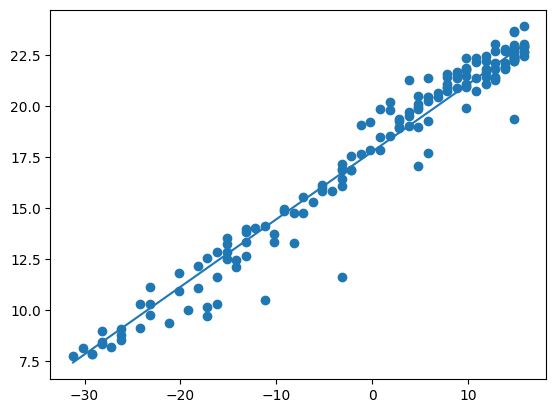

In [ ]:
# Make sure the line fits our data
Yhat = model.predict(X).flatten()
plt.scatter(X, Y)
plt.plot(X, Yhat)

In [ ]:
# Manual calculation

# Get the weights
w, b = model.layers[0].get_weights()

# Reshape X because we flattened it again earlier
X = X.reshape(-1, 1)

# (N x 1) x (1 x 1) + (1) --> (N x 1)
Yhat2 = (X.dot(w) + b).flatten()

# Don't use == for floating points
np.allclose(Yhat, Yhat2)

True